In [1]:
# Manipulação de dados
import pandas as pd
import numpy as np

# Visualização
import matplotlib.pyplot as plt
import seaborn as sns

# Preparação dos dados e Machine Learning
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, RobustScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight

# Exportação dos modelos
from joblib import dump

from pathlib import Path
import json
import warnings

warnings.filterwarnings("default")

# Caminho do arquivo tratado
ARQUIVO_TRATADO = Path(
    r"C:\Users\adriel_soares2\Documents\Projeto_Aero"
    r"\data\processed\dados_sensores_aeromotion_tratados.csv"
)

# Diretório para salvar os modelos e resultados
PASTA_MODELOS = ARQUIVO_TRATADO.parent / "modelos"
PASTA_MODELOS.mkdir(parents=True, exist_ok=True)

# Carrega os dados tratados
df_ml = pd.read_csv(ARQUIVO_TRATADO)

# Converte o timestamp para datetime
df_ml["timestamp"] = pd.to_datetime(
    df_ml["timestamp"],
    errors="coerce"
)

# Ordena cronologicamente os registros
df_ml = df_ml.sort_values("timestamp").reset_index(drop=True)

print("Dimensões:", df_ml.shape)
print("Período:", df_ml["timestamp"].min(), "até", df_ml["timestamp"].max())
print("\nColunas:")
print(df_ml.columns.tolist())

display(df_ml.head())

Dimensões: (12000, 20)
Período: 2026-01-01 00:00:00 até 2026-03-25 07:50:00

Colunas:
['timestamp', 'id_equipamento', 'modo_operacao', 'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'tipo_falha', 'temperatura_mancal_c_media_1h', 'temperatura_mancal_c_std_1h', 'temperatura_mancal_c_media_6h', 'temperatura_mancal_c_std_6h', 'vibracao_rms_mms_media_1h', 'vibracao_rms_mms_std_1h', 'vibracao_rms_mms_media_6h', 'vibracao_rms_mms_std_6h', 'severidade_dinamica']


,timestamp,id_equipamento,modo_operacao,horas_operacao_acumuladas,temperatura_mancal_c,vibracao_rms_mms,pressao_oleo_bar,rotacao_rpm,emissao_acustica_db,corrente_eletrica_amp,tipo_falha,temperatura_mancal_c_media_1h,temperatura_mancal_c_std_1h,temperatura_mancal_c_media_6h,temperatura_mancal_c_std_6h,vibracao_rms_mms_media_1h,vibracao_rms_mms_std_1h,vibracao_rms_mms_media_6h,vibracao_rms_mms_std_6h,severidade_dinamica
0,2026-01-01 00:00:00,TURB-103,Carga_Media,100.2,59.79,9.98,4.41,3006.8,48.96,39.68,2,59.790,NaN,59.790,NaN,9.980,NaN,9.980,NaN,0.003319
1,2026-01-01 00:10:00,TURB-104,Carga_Alta,100.5,79.49,3.13,4.50,3487.9,59.76,40.02,0,79.490,NaN,79.490,NaN,3.130,NaN,3.130,NaN,0.000897
2,2026-01-01 00:20:00,TURB-101,Cruzeiro,100.6,57.83,NaN,3.51,2382.7,44.97,18.73,0,57.830,NaN,57.830,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-01-01 00:30:00,TURB-103,Carga_Media,100.9,64.56,1.43,4.15,3019.9,53.05,27.36,0,62.175,3.372899,62.175,3.372899,5.705,6.045763,5.705,6.045763,0.000474
4,2026-01-01 00:40:00,TURB-103,Carga_Alta,101.1,70.80,3.44,4.91,3546.0,63.66,39.36,0,65.050,5.521331,65.050,5.521331,4.950,4.470537,4.950,4.470537,0.000970


Distribuição das classes:
tipo_falha
0    10560
1      600
2      480
3      360
Name: count, dtype: int64

Distribuição percentual:
tipo_falha
0    88.0
1     5.0
2     4.0
3     3.0
Name: proportion, dtype: float64


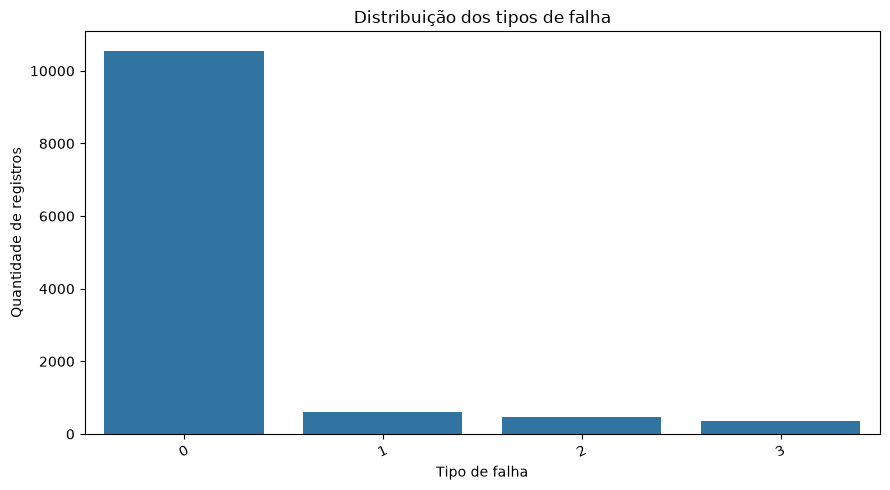

In [2]:
# Verifica se a variável-alvo existe
if "tipo_falha" not in df_ml.columns:
    raise ValueError("A coluna tipo_falha não foi encontrada.")

# Remove somente registros sem variável-alvo conhecida
# Não inventamos rótulos para observações sem classificação
df_ml = df_ml.dropna(subset=["tipo_falha"]).copy()

# Exibe a distribuição das classes
distribuicao = df_ml["tipo_falha"].value_counts().sort_index()

print("Distribuição das classes:")
print(distribuicao)

print("\nDistribuição percentual:")
print((df_ml["tipo_falha"].value_counts(normalize=True) * 100).round(2))

# Visualiza o balanceamento
plt.figure(figsize=(9, 5))
sns.countplot(data=df_ml, x="tipo_falha", order=distribuicao.index)
plt.title("Distribuição dos tipos de falha")
plt.xlabel("Tipo de falha")
plt.ylabel("Quantidade de registros")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [3]:
# Identifica a variável-alvo
ALVO = "tipo_falha"

# Colunas que não serão usadas diretamente como preditoras
COLUNAS_EXCLUIR = [
    ALVO,
    "timestamp",
    "id_equipamento"
]

# Seleciona as variáveis de entrada disponíveis
colunas_features = [
    coluna for coluna in df_ml.columns
    if coluna not in COLUNAS_EXCLUIR
]

X = df_ml[colunas_features].copy()
y = df_ml[ALVO].copy()

# Identifica variáveis categóricas e numéricas
colunas_categoricas = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

colunas_numericas = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

# Converte colunas categóricas para texto consistente
for coluna in colunas_categoricas:
    X[coluna] = X[coluna].astype("string")

# Verifica tipos de dados
print("Variáveis de entrada:", colunas_features)
print("\nVariáveis numéricas:", colunas_numericas)
print("Variáveis categóricas:", colunas_categoricas)

# Verifica valores ausentes
print("\nValores ausentes por variável:")
display(X.isna().sum().sort_values(ascending=False))

Variáveis de entrada: ['modo_operacao', 'horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'temperatura_mancal_c_media_1h', 'temperatura_mancal_c_std_1h', 'temperatura_mancal_c_media_6h', 'temperatura_mancal_c_std_6h', 'vibracao_rms_mms_media_1h', 'vibracao_rms_mms_std_1h', 'vibracao_rms_mms_media_6h', 'vibracao_rms_mms_std_6h', 'severidade_dinamica']

Variáveis numéricas: ['horas_operacao_acumuladas', 'temperatura_mancal_c', 'vibracao_rms_mms', 'pressao_oleo_bar', 'rotacao_rpm', 'emissao_acustica_db', 'corrente_eletrica_amp', 'temperatura_mancal_c_media_1h', 'temperatura_mancal_c_std_1h', 'temperatura_mancal_c_media_6h', 'temperatura_mancal_c_std_6h', 'vibracao_rms_mms_media_1h', 'vibracao_rms_mms_std_1h', 'vibracao_rms_mms_media_6h', 'vibracao_rms_mms_std_6h', 'severidade_dinamica']
Variáveis categóricas: ['modo_operacao']

Valores ausentes por variável:


temperatura_mancal_c_std_1h      3218
vibracao_rms_mms_std_1h          3188
emissao_acustica_db               484
temperatura_mancal_c              467
vibracao_rms_mms                  397
severidade_dinamica               397
pressao_oleo_bar                  328
temperatura_mancal_c_media_1h     133
vibracao_rms_mms_media_1h         113
vibracao_rms_mms_std_6h             6
temperatura_mancal_c_std_6h         4
vibracao_rms_mms_media_6h           1
modo_operacao                       0
corrente_eletrica_amp               0
rotacao_rpm                         0
horas_operacao_acumuladas           0
temperatura_mancal_c_media_6h       0
dtype: int64

In [4]:
# Ordena os índices cronologicamente antes de dividir
df_ml = df_ml.sort_values("timestamp").reset_index(drop=True)

# Recria X e y na mesma ordem temporal
colunas_features = [
    coluna for coluna in df_ml.columns
    if coluna not in ["tipo_falha", "timestamp", "id_equipamento"]
]

X = df_ml[colunas_features].copy()
y = df_ml["tipo_falha"].copy()

# Identifica as variáveis categóricas e numéricas
colunas_categoricas = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

colunas_numericas = X.select_dtypes(
    include=["number", "bool"]
).columns.tolist()

for coluna in colunas_categoricas:
    X[coluna] = X[coluna].astype("string")

# Ponto de corte temporal
indice_corte = int(len(df_ml) * 0.70)

X_treino = X.iloc[:indice_corte].copy()
X_teste = X.iloc[indice_corte:].copy()

y_treino = y.iloc[:indice_corte].copy()
y_teste = y.iloc[indice_corte:].copy()

print("Registros de treino:", len(X_treino))
print("Registros de teste:", len(X_teste))

print("\nPeríodo de treino:")
print(df_ml["timestamp"].iloc[0], "até",
      df_ml["timestamp"].iloc[indice_corte - 1])

print("\nPeríodo de teste:")
print(df_ml["timestamp"].iloc[indice_corte], "até",
      df_ml["timestamp"].iloc[-1])

print("\nClasses no treino:")
print(y_treino.value_counts().sort_index())

print("\nClasses no teste:")
print(y_teste.value_counts().sort_index())

# Verifica se todas as classes do teste aparecem no treino
classes_ausentes = set(y_teste.unique()) - set(y_treino.unique())

if classes_ausentes:
    print(
        "\nATENÇÃO: estas classes aparecem no teste, "
        "mas não no treino:",
        classes_ausentes
    )

Registros de treino: 8400
Registros de teste: 3600

Período de treino:
2026-01-01 00:00:00 até 2026-02-28 07:50:00

Período de teste:
2026-02-28 08:00:00 até 2026-03-25 07:50:00

Classes no treino:
tipo_falha
0    7401
1     417
2     329
3     253
Name: count, dtype: int64

Classes no teste:
tipo_falha
0    3159
1     183
2     151
3     107
Name: count, dtype: int64


In [5]:
# Pipeline para variáveis numéricas
pipeline_numerico = Pipeline(steps=[
    # Preenche valores ausentes pela mediana do treino
    ("imputer", SimpleImputer(strategy="median")),

    # Reduz a influência de valores extremos na escala
    ("scaler", RobustScaler())
])

# Pipeline para variáveis categóricas
pipeline_categorico = Pipeline(steps=[
    # Preenche categorias ausentes
    ("imputer", SimpleImputer(strategy="most_frequent")),

    # Converte categorias em variáveis binárias
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combina os dois pipelines
preprocessador = ColumnTransformer(
    transformers=[
        ("numericas", pipeline_numerico, colunas_numericas),
        ("categoricas", pipeline_categorico, colunas_categoricas)
    ],
    remainder="drop"
)

print("Pré-processamento configurado.")

Pré-processamento configurado.


In [6]:
# Configura validação cruzada temporal
validacao_temporal = TimeSeriesSplit(n_splits=3)

# Modelo 1: Random Forest
pipeline_rf = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("modelo", RandomForestClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

parametros_rf = {
    "modelo__n_estimators": [150, 300],
    "modelo__max_depth": [None, 15],
    "modelo__min_samples_leaf": [1, 3]
}

# Modelo 2: Extra Trees
pipeline_et = Pipeline(steps=[
    ("preprocessador", preprocessador),
    ("modelo", ExtraTreesClassifier(
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

parametros_et = {
    "modelo__n_estimators": [150, 300],
    "modelo__max_depth": [None, 15],
    "modelo__min_samples_leaf": [1, 3]
}

# Configura a busca de hiperparâmetros
busca_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=parametros_rf,
    scoring="f1_macro",
    cv=validacao_temporal,
    n_jobs=-1,
    verbose=1,
    refit=True
)

busca_et = GridSearchCV(
    estimator=pipeline_et,
    param_grid=parametros_et,
    scoring="f1_macro",
    cv=validacao_temporal,
    n_jobs=-1,
    verbose=1,
    refit=True
)

# Treina os dois modelos exclusivamente com os dados de treino
print("Treinando Random Forest...")
busca_rf.fit(X_treino, y_treino)

print("\nTreinando Extra Trees...")
busca_et.fit(X_treino, y_treino)

# Apresenta os melhores parâmetros
print("\nMelhores parâmetros — Random Forest:")
print(busca_rf.best_params_)
print("F1 macro na validação:", round(busca_rf.best_score_, 4))

print("\nMelhores parâmetros — Extra Trees:")
print(busca_et.best_params_)
print("F1 macro na validação:", round(busca_et.best_score_, 4))

Treinando Random Forest...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Treinando Extra Trees...
Fitting 3 folds for each of 8 candidates, totalling 24 fits

Melhores parâmetros — Random Forest:
{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 150}
F1 macro na validação: 0.9931

Melhores parâmetros — Extra Trees:
{'modelo__max_depth': None, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 150}
F1 macro na validação: 0.9921


In [7]:
# Seleciona os modelos com os melhores hiperparâmetros
modelos = {
    "Random Forest": busca_rf.best_estimator_,
    "Extra Trees": busca_et.best_estimator_
}

resultados = []
predicoes = {}

for nome, modelo in modelos.items():
    # Realiza as previsões no conjunto de teste
    y_pred = modelo.predict(X_teste)
    predicoes[nome] = y_pred

    # Calcula as métricas gerais
    resultados.append({
        "Modelo": nome,
        "Acurácia": accuracy_score(y_teste, y_pred),
        "Precisão macro": precision_score(
            y_teste, y_pred, average="macro", zero_division=0
        ),
        "Recall macro": recall_score(
            y_teste, y_pred, average="macro", zero_division=0
        ),
        "F1 macro": f1_score(
            y_teste, y_pred, average="macro", zero_division=0
        ),
        "F1 ponderado": f1_score(
            y_teste, y_pred, average="weighted", zero_division=0
        )
    })

    print(f"\n{'=' * 60}")
    print(f"RELATÓRIO — {nome}")
    print("=" * 60)

    print(classification_report(
        y_teste,
        y_pred,
        zero_division=0
    ))

# Compara os resultados
df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados.sort_values(
    "F1 macro",
    ascending=False
)

display(df_resultados.round(4))


RELATÓRIO — Random Forest
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      3159
           1       1.00      0.98      0.99       183
           2       0.99      0.99      0.99       151
           3       1.00      1.00      1.00       107

    accuracy                           1.00      3600
   macro avg       1.00      0.99      0.99      3600
weighted avg       1.00      1.00      1.00      3600


RELATÓRIO — Extra Trees
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      3159
           1       1.00      0.92      0.96       183
           2       0.99      0.97      0.98       151
           3       1.00      0.98      0.99       107

    accuracy                           0.99      3600
   macro avg       1.00      0.97      0.98      3600
weighted avg       0.99      0.99      0.99      3600



,Modelo,Acurácia,Precisão macro,Recall macro,F1 macro,F1 ponderado
0,Random Forest,0.9986,0.9965,0.9926,0.9945,0.9986
1,Extra Trees,0.9942,0.9951,0.9682,0.9812,0.9941


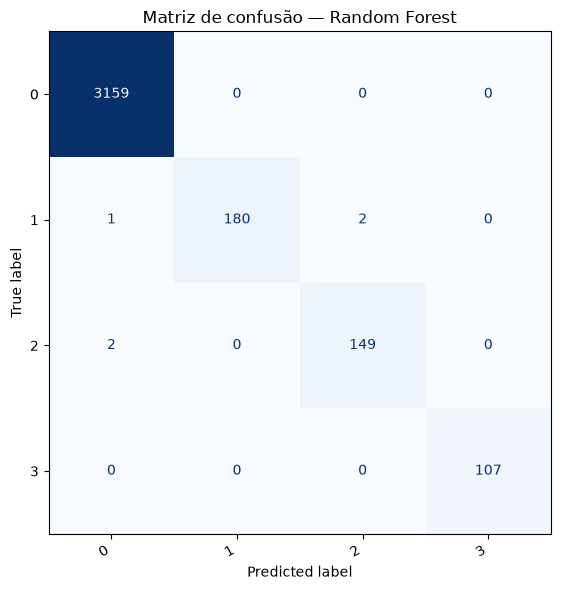

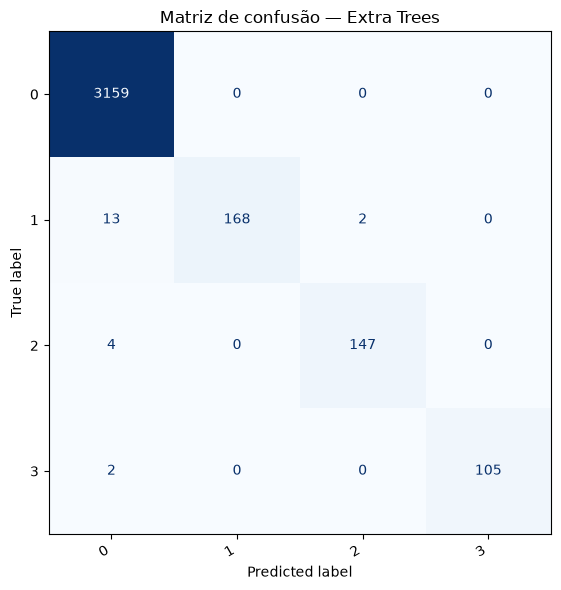

In [10]:
# Define a ordem das classes encontradas nos dados
classes = sorted(y.unique(), key=str)

for nome, y_pred in predicoes.items():
    matriz = confusion_matrix(
        y_teste,
        y_pred,
        labels=classes
    )

    visualizacao = ConfusionMatrixDisplay(
        confusion_matrix=matriz,
        display_labels=classes
    )

    fig, ax = plt.subplots(figsize=(8, 6))
    visualizacao.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    ax.set_title(f"Matriz de confusão — {nome}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

,Modelo,Classe,Precisão,Recall,F1-score,Suporte
0,Random Forest,0,0.9991,1.0000,0.9995,3159.0
1,Random Forest,1,1.0000,0.9836,0.9917,183.0
2,Random Forest,2,0.9868,0.9868,0.9868,151.0
3,Random Forest,3,1.0000,1.0000,1.0000,107.0
4,Extra Trees,0,0.9940,1.0000,0.9970,3159.0
5,Extra Trees,1,1.0000,0.9180,0.9573,183.0
6,Extra Trees,2,0.9866,0.9735,0.9800,151.0
7,Extra Trees,3,1.0000,0.9813,0.9906,107.0


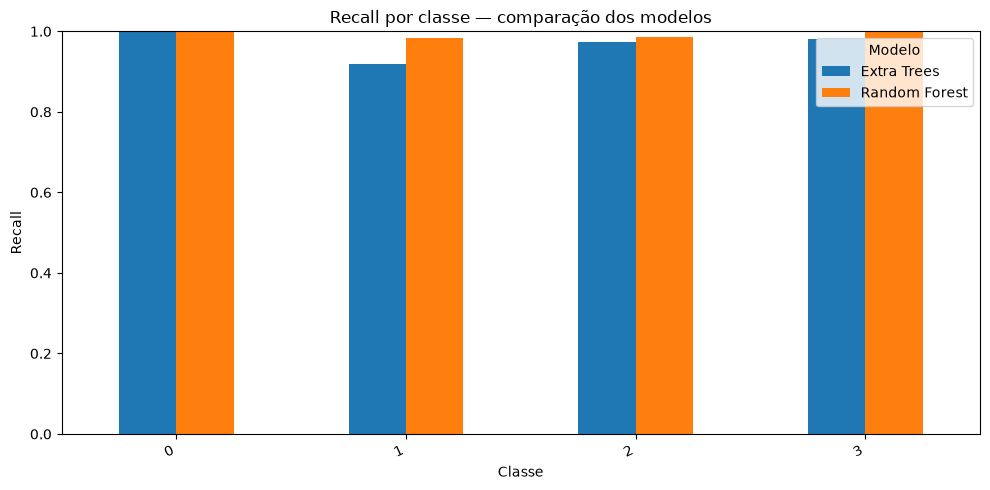

In [11]:
# Calcula as métricas detalhadas por classe
metricas_por_classe = []

for nome, y_pred in predicoes.items():
    relatorio = classification_report(
        y_teste,
        y_pred,
        labels=classes,
        output_dict=True,
        zero_division=0
    )

    for classe in classes:
        dados = relatorio[str(classe)]

        metricas_por_classe.append({
            "Modelo": nome,
            "Classe": str(classe),
            "Precisão": dados["precision"],
            "Recall": dados["recall"],
            "F1-score": dados["f1-score"],
            "Suporte": dados["support"]
        })

df_metricas_classe = pd.DataFrame(metricas_por_classe)

display(df_metricas_classe.round(4))

# Compara o recall por classe
grafico_recall = df_metricas_classe.pivot(
    index="Classe",
    columns="Modelo",
    values="Recall"
)

grafico_recall.plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1)
)

plt.title("Recall por classe — comparação dos modelos")
plt.xlabel("Classe")
plt.ylabel("Recall")
plt.xticks(rotation=25, ha="right")
plt.legend(title="Modelo")
plt.tight_layout()
plt.show()

Modelo selecionado: Random Forest


,Variável,Importância
5,numericas__emissao_acustica_db,0.17990
2,numericas__vibracao_rms_mms,0.13706
6,numericas__corrente_eletrica_amp,0.13672
3,numericas__pressao_oleo_bar,0.13355
15,numericas__severidade_dinamica,0.12294
1,numericas__temperatura_mancal_c,0.11597
11,numericas__vibracao_rms_mms_media_1h,0.04252
7,numericas__temperatura_mancal_c_media_1h,0.04144
8,numericas__temperatura_mancal_c_std_1h,0.01828
10,numericas__temperatura_mancal_c_std_6h,0.01734


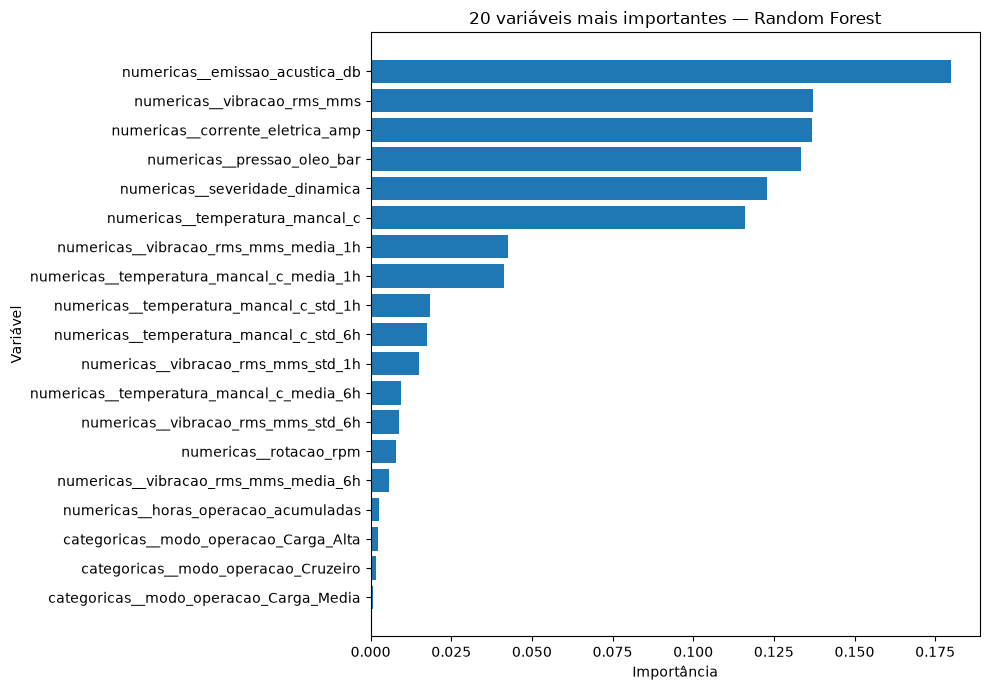

In [12]:
# Seleciona o modelo com maior F1 macro no teste
melhor_nome = df_resultados.iloc[0]["Modelo"]
melhor_modelo = modelos[melhor_nome]

# Recupera os nomes das variáveis após o pré-processamento
nomes_features = (
    melhor_modelo
    .named_steps["preprocessador"]
    .get_feature_names_out()
)

# Obtém as importâncias do classificador
importancias = melhor_modelo.named_steps["modelo"].feature_importances_

df_importancias = pd.DataFrame({
    "Variável": nomes_features,
    "Importância": importancias
}).sort_values("Importância", ascending=False)

print("Modelo selecionado:", melhor_nome)
display(df_importancias.head(20).round(5))

# Gráfico das 20 variáveis mais importantes
top_features = df_importancias.head(20).sort_values("Importância")

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Variável"],
    top_features["Importância"]
)
plt.title(f"20 variáveis mais importantes — {melhor_nome}")
plt.xlabel("Importância")
plt.ylabel("Variável")
plt.tight_layout()
plt.show()

In [13]:
from sklearn.ensemble import IsolationForest
from sklearn.base import clone

# Identifica a classe normal conforme o esquema do projeto
# Ajuste para "Normal" se os rótulos forem textuais.
CLASSE_NORMAL = 0

# Separa os registros normais do conjunto de treino
mascara_normal = y_treino == CLASSE_NORMAL

if mascara_normal.sum() == 0:
    raise ValueError(
        "Não existem registros normais no treino. "
        "Verifique o valor utilizado em CLASSE_NORMAL."
    )

# Ajusta um pré-processador independente usando somente dados normais
preprocessador_anomalia = clone(preprocessador)

X_treino_normal = X_treino.loc[mascara_normal]

X_normal_transformado = preprocessador_anomalia.fit_transform(
    X_treino_normal
)

# Treina o detector de anomalias exclusivamente com dados normais
detector_anomalias = IsolationForest(
    n_estimators=200,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

detector_anomalias.fit(X_normal_transformado)

# Avalia as anomalias nos dados de teste
X_teste_transformado = preprocessador_anomalia.transform(X_teste)

# 1 = normal; -1 = anomalia
predicoes_anomalia = detector_anomalias.predict(
    X_teste_transformado
)

print("Registros de teste:", len(X_teste))
print(
    "Anomalias detectadas:",
    int((predicoes_anomalia == -1).sum())
)
print(
    "Percentual de anomalias detectadas:",
    round((predicoes_anomalia == -1).mean() * 100, 2),
    "%"
)

Registros de teste: 3600
Anomalias detectadas: 1148
Percentual de anomalias detectadas: 31.89 %


In [14]:
# Exporta os melhores pipelines de classificação
dump(
    busca_rf.best_estimator_,
    PASTA_MODELOS / "random_forest.joblib"
)

dump(
    busca_et.best_estimator_,
    PASTA_MODELOS / "extra_trees.joblib"
)

# Exporta o detector de anomalias e seu pré-processador
dump(
    detector_anomalias,
    PASTA_MODELOS / "isolation_forest.joblib"
)

dump(
    preprocessador_anomalia,
    PASTA_MODELOS / "preprocessador_anomalias.joblib"
)

# Salva as métricas e a importância das variáveis
df_resultados.to_csv(
    PASTA_MODELOS / "comparacao_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

df_metricas_classe.to_csv(
    PASTA_MODELOS / "metricas_por_classe.csv",
    index=False,
    encoding="utf-8-sig"
)

df_importancias.to_csv(
    PASTA_MODELOS / "importancia_variaveis.csv",
    index=False,
    encoding="utf-8-sig"
)

# Salva metadados básicos para identificar o treinamento
metadados = {
    "arquivo_origem": str(ARQUIVO_TRATADO),
    "variavel_alvo": ALVO,
    "melhor_modelo_por_f1_macro_teste": melhor_nome,
    "quantidade_treino": int(len(X_treino)),
    "quantidade_teste": int(len(X_teste)),
    "classes": [str(classe) for classe in classes],
    "variaveis_entrada": colunas_features
}

with open(
    PASTA_MODELOS / "metadados_treinamento.json",
    "w",
    encoding="utf-8"
) as arquivo:
    json.dump(
        metadados,
        arquivo,
        ensure_ascii=False,
        indent=4
    )

print("Arquivos exportados para:", PASTA_MODELOS)

Arquivos exportados para: C:\Users\adriel_soares2\Documents\Projeto_Aero\data\processed\modelos
